# 01. Deep Dive — Identifier


In [42]:
from math import ceil
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from propensity.overview import build_dunnhumby_overview
from propensity.overview.activity_dashboard import (
    load_transaction_activity_dashboard,
    plot_transaction_activity_dashboard,
)
from propensity.schema.dunnhumby import DUNNHUMBY_CATALOG

In [43]:
raw_dir = Path("../data/raw/Dunnhumby")
report = build_dunnhumby_overview(raw_dir=raw_dir)

In [ ]:
product_taxonomy = pd.read_csv(
    raw_dir / "product.csv",
    usecols=["PRODUCT_ID", "MANUFACTURER"],
)
manufacturer_by_product = (
    product_taxonomy
    .drop_duplicates("PRODUCT_ID")
    .set_index("PRODUCT_ID")["MANUFACTURER"]
)
transaction_detail = pd.read_csv(
    raw_dir / "transaction_data.csv",
    usecols=[
        "household_key", "BASKET_ID", "DAY",
        "PRODUCT_ID", "STORE_ID",
    ],
)
transaction_detail["MANUFACTURER"] = transaction_detail["PRODUCT_ID"].map(
    manufacturer_by_product
)


## 3. Candidate Grain Summary

In [47]:
report.grain_summary

,table,grain,n_rows,complete_key_rows,missing_key_rows,unique_groups,duplicate_groups,excess_rows,max_rows_per_group,is_unique,is_valid
0,transaction,"BASKET_ID, PRODUCT_ID",2595732,2595732,0,2595732,0,0,1,True,True
1,product,PRODUCT_ID,92353,92353,0,92353,0,0,1,True,True
2,demographic,household_key,801,801,0,801,0,0,1,True,True
3,campaign_desc,CAMPAIGN,30,30,0,30,0,0,1,True,True
4,campaign_table,"CAMPAIGN, household_key",7208,7208,0,7208,0,0,1,True,True
5,coupon,"COUPON_UPC, PRODUCT_ID, CAMPAIGN",124548,124548,0,117560,1824,5164,19,False,False
6,coupon_redempt,"household_key, DAY, COUPON_UPC, CAMPAIGN",2318,2318,0,2318,0,0,1,True,True
7,causal,"PRODUCT_ID, STORE_ID, WEEK_NO",36786524,36786524,0,36756034,15245,15245,2,False,False


Coupon có 1824 (%) duplicate,  causal có 15245(%),
0% missing row
-> cần kiểm tra casual lại có khác display hay mailer không 

## 4. Identifier Key Summary

In [48]:
report.identifier_summary

,table,column,n_rows,n_missing,missing_pct,n_unique_non_missing,is_unique,is_valid
0,transaction,household_key,2595732,0,0.0,2500,False,False
1,transaction,BASKET_ID,2595732,0,0.0,276484,False,False
2,transaction,PRODUCT_ID,2595732,0,0.0,92339,False,False
3,transaction,STORE_ID,2595732,0,0.0,582,False,False
4,product,PRODUCT_ID,92353,0,0.0,92353,True,True
5,product,MANUFACTURER,92353,0,0.0,6476,False,False
6,demographic,household_key,801,0,0.0,801,True,True
7,campaign_desc,CAMPAIGN,30,0,0.0,30,True,True
8,campaign_table,CAMPAIGN,7208,0,0.0,30,False,False
9,campaign_table,household_key,7208,0,0.0,1584,False,False


#### Household summary và key-frequency plots

In [58]:
hh = (
    transaction_detail
    .groupby("household_key", as_index=False)
    .agg(
        n_lines=("PRODUCT_ID", "size"),
        n_baskets=("BASKET_ID", "nunique"),
        n_active_days=("DAY", "nunique"),
        first_day=("DAY", "min"),
        last_day=("DAY", "max"),
    )
)
hh["span_days"] = hh["last_day"] - hh["first_day"] + 1
hh = hh.sort_values(["n_baskets", "household_key"], ascending=[False, True])
hh

,household_key,n_lines,n_baskets,n_active_days,first_day,last_day,span_days
1509,1510,4813,1300,504,82,711,630
899,900,4080,1223,521,62,711,650
2336,2337,5517,1210,444,114,709,596
1794,1795,4703,1138,494,89,710,622
2458,2459,6646,971,450,35,704,670
...,...,...,...,...,...,...,...
1726,1727,18,2,2,109,118,10
2200,2201,12,2,2,48,72,25
493,494,4,1,1,94,94,1
1829,1830,7,1,1,69,69,1


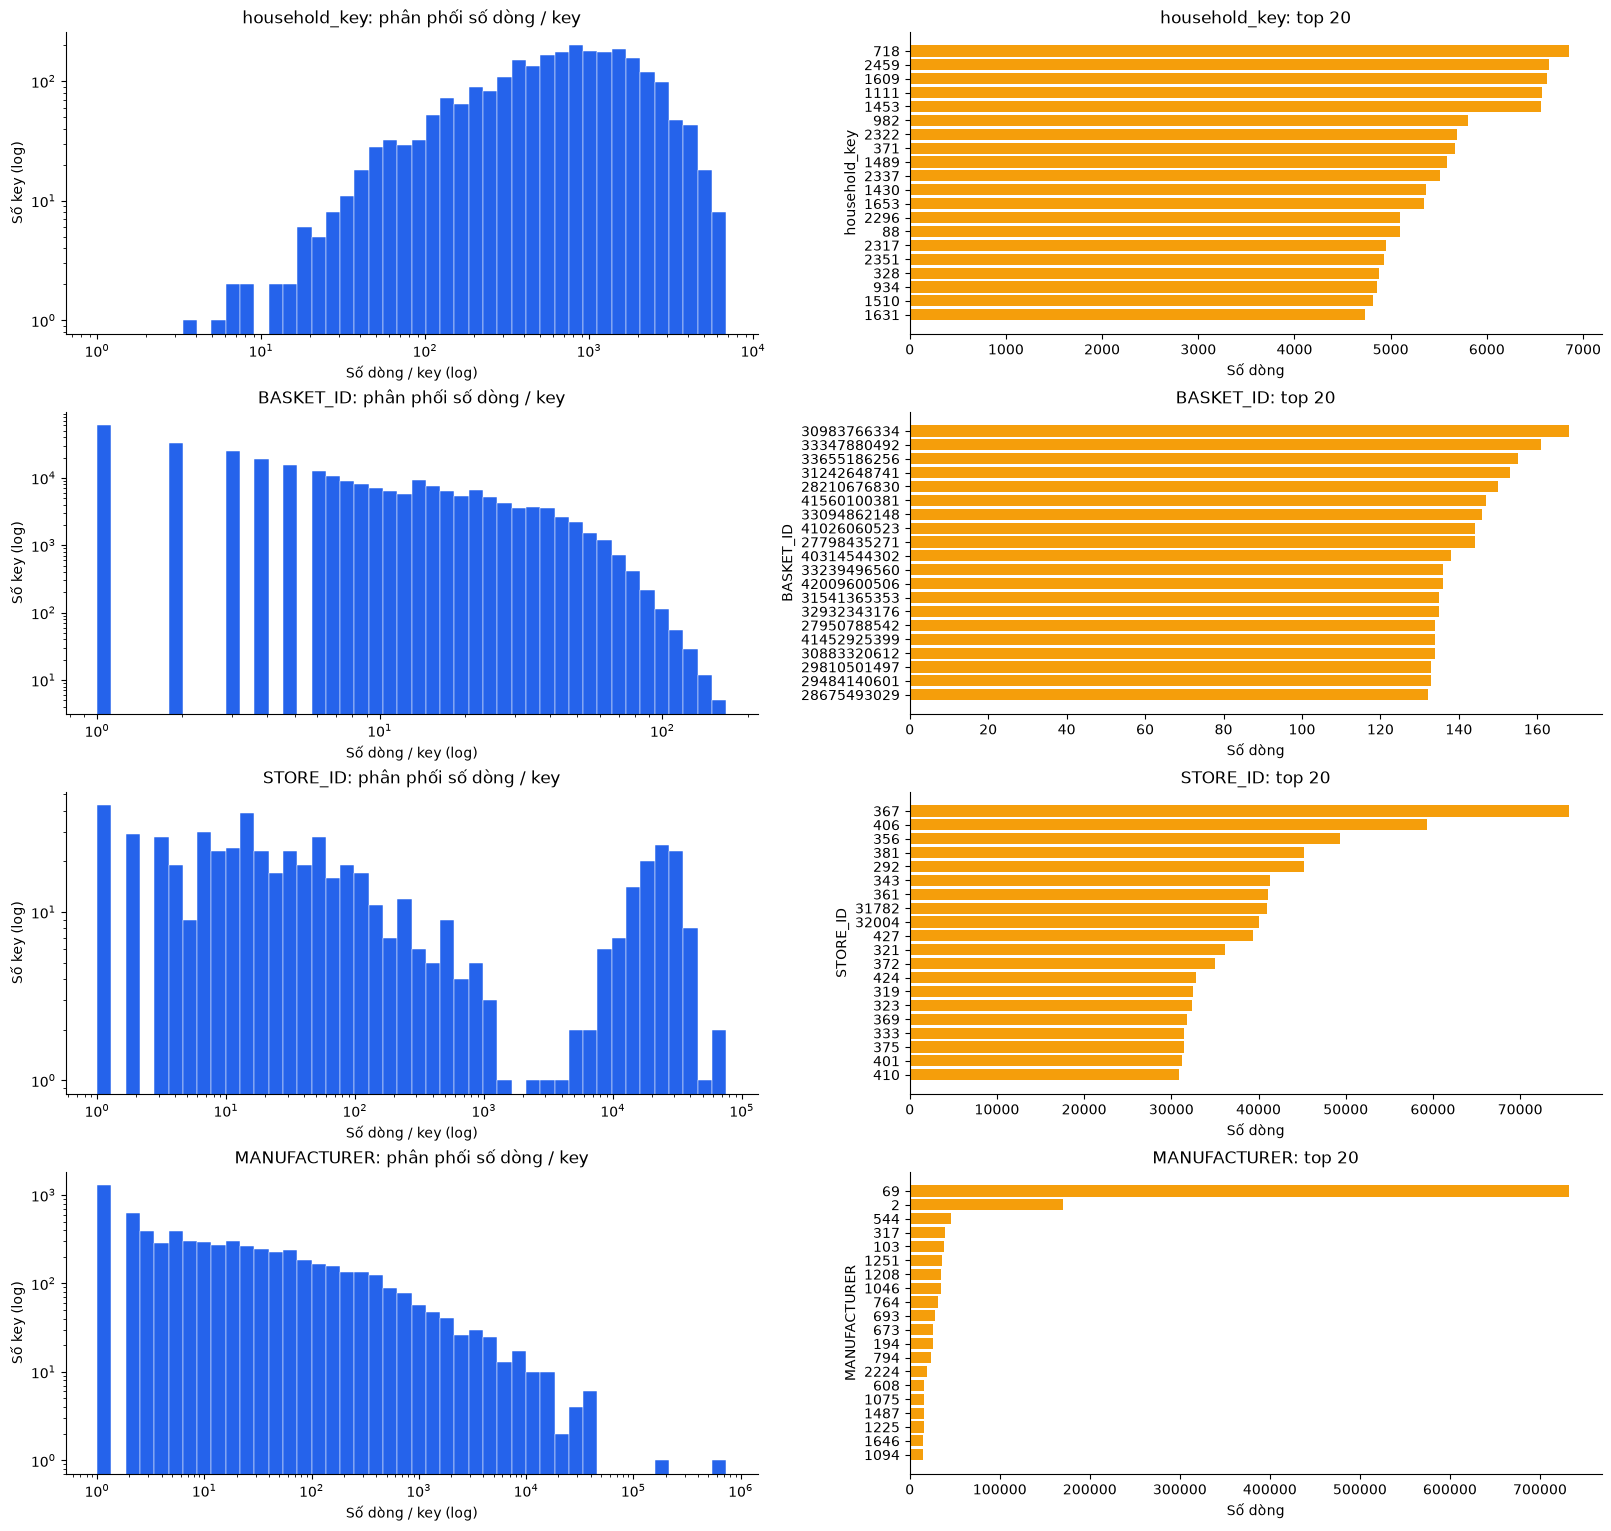

In [59]:
KEY_FREQUENCY_TOP_N = 20
key_frequency_columns = ["household_key", "BASKET_ID", "STORE_ID", "MANUFACTURER"]
key_frequency_counts = {
    column: transaction_detail[column].value_counts(dropna=False)
    for column in key_frequency_columns
}
key_frequency_figure, key_frequency_axes = plt.subplots(
    len(key_frequency_columns), 2,
    figsize=(16, 3.8 * len(key_frequency_columns)),
    layout="constrained",
)
for row_index, column in enumerate(key_frequency_columns):
    frequencies = key_frequency_counts[column].astype("float64")
    histogram_axis, top_axis = key_frequency_axes[row_index]
    frequency_max = max(2.0, float(frequencies.max()))
    frequency_bins = np.unique(np.geomspace(1, frequency_max, 45))
    histogram_axis.hist(
        frequencies, bins=frequency_bins,
        color="#2563EB", edgecolor="white", linewidth=0.35,
    )
    histogram_axis.set_xscale("log")
    histogram_axis.set_yscale("log")
    histogram_axis.set(
        title=f"{column}: phân phối số dòng / key",
        xlabel="Số dòng / key (log)", ylabel="Số key (log)",
    )
    top_frequencies = frequencies.nlargest(KEY_FREQUENCY_TOP_N).sort_values()
    top_axis.barh(
        [str(value) for value in top_frequencies.index],
        top_frequencies.values, color="#F59E0B",
    )
    top_axis.set(
        title=f"{column}: top {KEY_FREQUENCY_TOP_N}",
        xlabel="Số dòng", ylabel=column,
    )
    for axis in (histogram_axis, top_axis):
        axis.spines[["top", "right"]].set_visible(False)
plt.show()

In [76]:
(frequencies.nlargest(KEY_FREQUENCY_TOP_N).sort_values().sum())/(frequencies.nlargest(2500).sort_values().sum())

np.float64(0.5349426009768891)